# Lab 3 - Trenowanie sieci w Keras: klasyfikacja, regresja i regularyzacja

> **Wersja dla studentów.** Komórki z `# TODO` uzupełnij samodzielnie.

**Kurs:** Uczenie głębokie (Informatyka, II stopień, sem. III, studia niestacjonarne)
**Prowadząca:** dr inż. Natalia Piórkowska
**Środowisko:** Google Colab, GPU T4, TensorFlow / Keras 3

## Cel zajęć

Na poprzednich zajęciach (L1, L2) budowaliśmy sieci "od zera" - liczyliśmy gradienty ręcznie, pisaliśmy własne pętle treningowe. Dziś przechodzimy na poziom, na którym pracuje się na co dzień: **wysokopoziomowe API Keras**. Nauczysz się:

1. budować i trenować sieć MLP do **klasyfikacji wieloklasowej** (Fashion-MNIST) z warstwą softmax i stratą `sparse_categorical_crossentropy`,
2. czytać **krzywe uczenia** i diagnozować niedouczenie / przeuczenie,
3. budować sieć do **regresji** (California Housing), poprawnie standaryzować dane (tylko na zbiorze treningowym!) i porównywać się z **baseline'em**,
4. używać **callbacków**: `EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`,
5. porównywać **optymalizatory** (SGD, SGD+momentum, RMSprop, Adam) i dobierać **learning rate**,
6. celowo **przeuczyć** sieć, a potem ją "leczyć": Dropout, regularyzacja L2, BatchNormalization,
7. **zapisywać i wczytywać** modele w formacie `.keras`.

## Efekty uczenia (z karty przedmiotu)

- **UGŁ_W01** - zna metody uczenia sieci (funkcje straty, optymalizatory, regularyzacja).
- **UGŁ_W02** - zna zaawansowane narzędzia DL (Keras, callbacki, zapis modeli - element cyklu życia modelu).
- **UGŁ_U01** - formułuje i weryfikuje hipotezy (np. "Dropout zmniejszy różnicę między train a val").
- **UGŁ_U02** - proponuje usprawnienia rozwiązania w oparciu o istniejące biblioteki.

## Powiązanie z wykładem

- **W1** - parametry vs hiperparametry, podział train/val/test, overfitting/underfitting.
- **W2** - warstwa gęsta, aktywacje, softmax, BatchNorm, Dropout.
- **W3** - funkcje straty (MSE, MAE, CCE), optymalizatory (SGD, momentum, RMSProp, Adam), regularyzacja, krzywe uczenia, Keras: `compile` / `fit` / `evaluate`, callbacki. **To główny wykład do tych zajęć.**
- **W4** - metryki klasyfikacji i regresji (zapowiedź - pełna analiza w L5).

## Harmonogram (180 min)

| Czas | Blok |
|---|---|
| 0-10 min | Wstęp, przygotowanie środowiska (sekcja 0) |
| 10-45 min | 1. Klasyfikacja Fashion-MNIST: MLP, softmax, krzywe uczenia (zad. 1.1, 1.2) |
| 45-75 min | 2. Regresja California Housing: standaryzacja, baseline, MSE/MAE (zad. 2.1, 2.2) |
| 75-95 min | 3. Callbacki (zad. 3.1) |
| 95-105 min | **Przerwa (10 min)** |
| 105-130 min | 4. Optymalizatory i learning rate (zad. 4.1, 4.2) |
| 130-160 min | 5. Przeuczenie i regularyzacja: Dropout, L2, BatchNorm (zad. 5.1, 5.2) |
| 160-170 min | 6. Zapis i wczytanie modelu (zad. 6.1) |
| 170-180 min | Pytania kontrolne, podsumowanie, informacje do sprawozdania |

## Wymagania wstępne

- Python, NumPy, matplotlib na poziomie L1-L2.
- Rozumienie: czym jest funkcja straty, gradient, epoka, batch (L1), jak działa MLP i backpropagation (L2).
- Znajomość podziału na zbiór treningowy, walidacyjny i testowy (W1).

## 0. Przygotowanie środowiska

### Włączenie GPU w Colab
W menu wybierz: **Środowisko wykonawcze -> Zmień typ środowiska wykonawczego -> T4 GPU -> Zapisz**. Po zmianie środowisko zostanie zrestartowane, więc zrób to **przed** uruchomieniem pierwszej komórki.

### Tryb szybki
Zmienna `SZYBKI_TRYB` steruje "budżetem obliczeniowym" notebooka. Gdy `SZYBKI_TRYB = True`:
- używamy tylko części danych (np. 2000 pierwszych obrazów),
- trenujemy tylko przez 2-3 epoki.

Wyniki będą wtedy słabsze, ale cały notebook przejdzie w kilka minut nawet na CPU. **Przełącz na `True`, jeśli pracujesz bez GPU** (np. limit GPU w Colab się wyczerpał) albo chcesz najpierw sprawdzić, czy kod działa. Domyślnie wartość jest odczytywana ze zmiennej środowiskowej `DL_FAST` (na zajęciach w Colab będzie to `False`).

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
import keras
from keras import layers

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, confusion_matrix

# Tryb szybki: True = mniej danych i epok (praca na CPU / szybki test kodu)
SZYBKI_TRYB = os.environ.get("DL_FAST", "0") == "1"
# SZYBKI_TRYB = True   # <- odkomentuj, jeśli pracujesz bez GPU

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("Backend Keras:", keras.backend.backend())
print("SZYBKI_TRYB =", SZYBKI_TRYB)

TensorFlow: 2.21.0 | Keras: 3.13.2
Backend Keras: tensorflow
SZYBKI_TRYB = False


In [2]:
# Sprawdzenie dostępności GPU
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    print("Dostępne GPU:", gpus)
else:
    print("Brak GPU - obliczenia na CPU. Rozważ SZYBKI_TRYB = True.")

# Ziarno losowości: ustawia jednocześnie seed dla Pythona, NumPy i TensorFlow.
# Dzięki temu wyniki są (w przybliżeniu) powtarzalne - na GPU drobne różnice i tak mogą wystąpić.
SEED = 42
keras.utils.set_random_seed(SEED)

Dostępne GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Funkcja pomocnicza do rysowania krzywych uczenia

Obiekt `History` zwracany przez `model.fit(...)` ma słownik `history.history`, w którym dla każdej metryki zapisana jest lista wartości z kolejnych epok, np. `loss`, `val_loss`, `accuracy`, `val_accuracy`. Napiszmy funkcję, której będziemy używać przez cały notebook.

In [3]:
def rysuj_historie(historia, metryka="accuracy", tytul=""):
    # Rysuje stratę i wybraną metrykę dla zbioru treningowego i walidacyjnego
    h = historia.history if hasattr(historia, "history") else historia
    epoki = np.arange(1, len(h["loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(epoki, h["loss"], "o-", label="train")
    if "val_loss" in h:
        ax[0].plot(epoki, h["val_loss"], "s-", label="walidacja")
    ax[0].set_xlabel("epoka"); ax[0].set_ylabel("strata"); ax[0].set_title(f"{tytul} - strata")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    if metryka in h:
        ax[1].plot(epoki, h[metryka], "o-", label="train")
        if "val_" + metryka in h:
            ax[1].plot(epoki, h["val_" + metryka], "s-", label="walidacja")
        ax[1].set_xlabel("epoka"); ax[1].set_ylabel(metryka); ax[1].set_title(f"{tytul} - {metryka}")
        ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 1. Klasyfikacja wieloklasowa: Fashion-MNIST

### Zbiór danych
Fashion-MNIST to 70 000 obrazów w skali szarości 28x28 przedstawiających 10 kategorii ubrań (60 000 treningowych, 10 000 testowych). Jest trudniejszy niż klasyczny MNIST (cyfry), dlatego lepiej pokazuje różnice między modelami.

### Podział danych - przypomnienie z W1
- **train** - na nim model uczy się parametrów (wag),
- **walidacja (val)** - na nim wybieramy hiperparametry i decydujemy, kiedy przerwać trening,
- **test** - używamy go **raz, na końcu**, do uczciwej oceny. Jeśli patrzymy na test przy dobieraniu hiperparametrów, wynik testowy staje się optymistycznie obciążony.

Keras dostarcza tylko train i test, więc walidację wydzielimy sami z części treningowej.

In [4]:
(x_tr_full, y_tr_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

if SZYBKI_TRYB:
    # w trybie szybkim bierzemy tylko początkowe próbki
    x_tr_full, y_tr_full = x_tr_full[:2000], y_tr_full[:2000]
    x_test, y_test = x_test[:500], y_test[:500]

# Normalizacja do [0, 1]: sieci uczą się znacznie stabilniej na małych wartościach niż na 0..255
x_tr_full = x_tr_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Wydzielamy walidację: ostatnia 1/6 części treningowej (w pełnym trybie 10 000 obrazów)
n_val = len(x_tr_full) // 6
x_train, y_train = x_tr_full[:-n_val], y_tr_full[:-n_val]
x_val, y_val = x_tr_full[-n_val:], y_tr_full[-n_val:]

NAZWY_KLAS = ["T-shirt/top", "Spodnie", "Sweter", "Sukienka", "Płaszcz",
              "Sandał", "Koszula", "Sneaker", "Torba", "Botek"]

print("train:", x_train.shape, "val:", x_val.shape, "test:", x_test.shape)
print("zakres wartości:", x_train.min(), "-", x_train.max())
print("liczność klas w train:", np.bincount(y_train, minlength=10))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (50000, 28, 28) val: (10000, 28, 28) test: (10000, 28, 28)
zakres wartości: 0.0 - 1.0
liczność klas w train: [4977 5012 4992 4979 4950 5004 5030 5045 5032 4979]


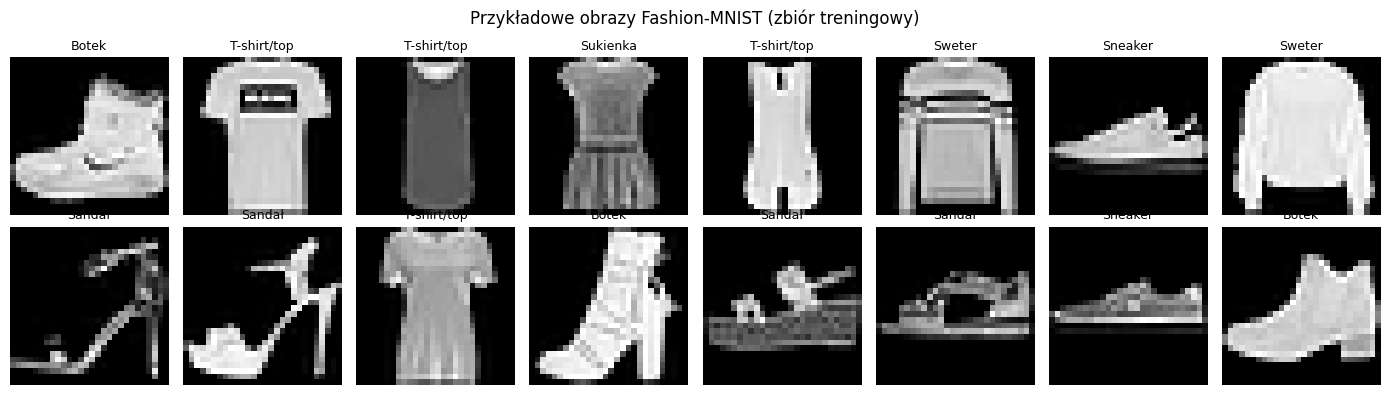

In [5]:
# Podgląd kilku obrazów z etykietami
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(NAZWY_KLAS[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Przykładowe obrazy Fashion-MNIST (zbiór treningowy)")
plt.tight_layout(); plt.show()

### Softmax i entropia krzyżowa

Ostatnia warstwa klasyfikatora na $K$ klas ma $K$ neuronów zwracających liczby rzeczywiste $z_1, \dots, z_K$ (tzw. **logity**). Funkcja **softmax** zamienia je na rozkład prawdopodobieństwa:

$$p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad \sum_k p_k = 1.$$

Funkcja straty **kategorialnej entropii krzyżowej** dla jednej próbki z prawdziwą klasą $y$ to

$$L = -\log p_y.$$

Intuicja: jeśli model daje prawdziwej klasie prawdopodobieństwo bliskie 1, strata jest bliska 0; jeśli bliskie 0, strata rośnie do nieskończoności - model jest mocno karany za pewne, ale błędne odpowiedzi.

### `sparse_categorical_crossentropy` vs `categorical_crossentropy`
- `categorical_crossentropy` - etykiety w postaci **one-hot**, np. klasa 3 -> `[0,0,0,1,0,0,0,0,0,0]`,
- `sparse_categorical_crossentropy` - etykiety jako **liczby całkowite** (0..9). Matematycznie to ta sama strata, ale nie trzeba tworzyć macierzy one-hot.

Nasze `y_train` to liczby całkowite, więc użyjemy wersji `sparse_`. **Typowy błąd:** użycie `categorical_crossentropy` z etykietami całkowitymi - Keras zgłosi błąd niezgodności kształtów.

### Ile parametrów ma warstwa gęsta? (W2)
Warstwa `Dense(n_out)` przy wejściu o wymiarze $n_{in}$ ma $n_{in} \cdot n_{out} + n_{out}$ parametrów (wagi + biasy). Dla `Flatten` 28x28 = 784 wejść i 128 neuronów: $784 \cdot 128 + 128 = 100\,480$.

In [6]:
# Model demonstracyjny: najprostszy MLP z jedną warstwą ukrytą
model_demo = keras.Sequential([
    keras.Input(shape=(28, 28)),            # deklaracja kształtu wejścia (bez wymiaru batcha)
    layers.Flatten(),                       # 28x28 -> wektor 784
    layers.Dense(128, activation="relu"),   # warstwa ukryta
    layers.Dense(10, activation="softmax"), # 10 klas -> rozkład prawdopodobieństwa
], name="mlp_demo")

model_demo.summary()   # sprawdź: 100 480 + 1 290 = 101 770 parametrów

Model: "mlp_demo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### `compile` i `fit`

- `compile(optimizer, loss, metrics)` - konfiguruje trening: czym optymalizujemy, co minimalizujemy i co dodatkowo raportujemy.
- `fit(x, y, epochs, batch_size, validation_data)` - właściwy trening. W każdej epoce model przechodzi raz przez cały zbiór treningowy w porcjach (mini-batchach) po `batch_size` próbek. Po każdej epoce liczone są metryki na zbiorze walidacyjnym.
- `evaluate(x, y)` - liczy stratę i metryki na podanym zbiorze, bez uczenia.

Epoch 1/10
391/391 - 12s - 30ms/step - accuracy: 0.8046 - loss: 0.5727 - val_accuracy: 0.8324 - val_loss: 0.4694
Epoch 2/10
391/391 - 1s - 3ms/step - accuracy: 0.8525 - loss: 0.4164 - val_accuracy: 0.8604 - val_loss: 0.4050
Epoch 3/10
391/391 - 1s - 3ms/step - accuracy: 0.8673 - loss: 0.3761 - val_accuracy: 0.8692 - val_loss: 0.3778
Epoch 4/10
391/391 - 1s - 3ms/step - accuracy: 0.8757 - loss: 0.3488 - val_accuracy: 0.8738 - val_loss: 0.3638
Epoch 5/10
391/391 - 1s - 3ms/step - accuracy: 0.8828 - loss: 0.3274 - val_accuracy: 0.8785 - val_loss: 0.3534
Epoch 6/10
391/391 - 1s - 3ms/step - accuracy: 0.8882 - loss: 0.3111 - val_accuracy: 0.8802 - val_loss: 0.3466
Epoch 7/10
391/391 - 1s - 3ms/step - accuracy: 0.8926 - loss: 0.2968 - val_accuracy: 0.8819 - val_loss: 0.3442
Epoch 8/10
391/391 - 1s - 3ms/step - accuracy: 0.8971 - loss: 0.2848 - val_accuracy: 0.8812 - val_loss: 0.3419
Epoch 9/10
391/391 - 2s - 5ms/step - accuracy: 0.9009 - loss: 0.2733 - val_accuracy: 0.8814 - val_loss: 0.3425

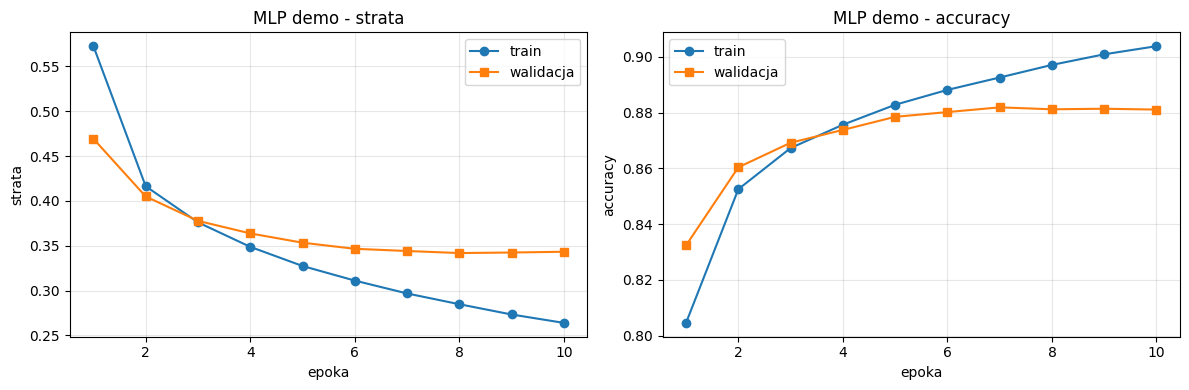

In [7]:
EPOKI_DEMO = 2 if SZYBKI_TRYB else 10

model_demo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

t0 = time.time()
hist_demo = model_demo.fit(
    x_train, y_train,
    epochs=EPOKI_DEMO,
    batch_size=128,
    validation_data=(x_val, y_val),   # walidacja liczona po każdej epoce
    verbose=2,                        # jedna linia na epokę
)
print(f"czas treningu: {time.time() - t0:.1f} s")
rysuj_historie(hist_demo, tytul="MLP demo")

### Jak czytać krzywe uczenia (W3)?

| Obserwacja | Diagnoza | Co zrobić |
|---|---|---|
| strata train i val wysokie, zbliżone | **niedouczenie** (underfitting) | większy model, dłuższy trening, większy lr |
| strata train maleje, val maleje i stabilizuje się | dobre dopasowanie | ewentualnie zatrzymać w minimum val |
| strata train maleje, val zaczyna **rosnąć** | **przeuczenie** (overfitting) | regularyzacja, więcej danych, early stopping |
| strata skacze / rośnie od początku | za duży learning rate, błąd w danych | zmniejszyć lr, sprawdzić dane |

Uwaga: w pierwszych epokach dokładność walidacyjna bywa **wyższa** niż treningowa. To nie błąd - metryki treningowe są uśredniane w trakcie epoki (model na początku epoki był gorszy), a walidacyjne liczone na końcu epoki.

### Zadanie 1.1 - Głębszy MLP

Zbuduj model `model_mlp` (Sequential) o architekturze:
`Input(28,28) -> Flatten -> Dense(256, relu) -> Dense(128, relu) -> Dense(10, softmax)`.

1. Skompiluj go z optymalizatorem Adam (lr = 1e-3), stratą `sparse_categorical_crossentropy` i metryką `accuracy`.
2. Wytrenuj przez `EPOKI_11` epok z `batch_size=128`, z walidacją na `(x_val, y_val)`. Historię zapisz w `hist_mlp`.
3. Narysuj krzywe uczenia funkcją `rysuj_historie`.
4. Oceń model na zbiorze **testowym** (`evaluate`) i wypisz dokładność.
5. Ręcznie policz liczbę parametrów i porównaj z `model_mlp.count_params()`.

**Kryteria sukcesu (pełny tryb, GPU):** dokładność walidacyjna >= 0.87, testowa >= 0.86; liczba parametrów zgadza się z Twoim rachunkiem.

**Wskazówki:** wzorem jest `model_demo` powyżej. Parametry: $784\cdot256+256$, $256\cdot128+128$, $128\cdot10+10$.

Model: "mlp_256_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
391/391 - 5s - 13ms/step - accuracy: 0.8163 - loss: 0.5223 - val_accuracy: 0.8584 - val_loss: 0.4124
Epoch 2/15
391/391 - 1s - 4ms/step - accuracy: 0.8625 - loss: 0.3785 - val_accuracy: 0.8657 - val_loss: 0.3858
Epoch 3/15
391/391 - 1s - 3ms/step - accuracy: 0.8763 - loss: 0.3372 - val_accuracy: 0.8742 - val_loss: 0.3582
Epoch 4/15
391/391 - 1s - 3ms/step - accuracy: 0.8857 - loss: 0.3108 - val_accuracy: 0.8758 - val_loss: 0.3432
Epoch 5/15
391/391 - 2s - 6ms/step - accuracy: 0.8932 - loss: 0.2909 - val_accuracy: 0.8769 - val_loss: 0.3424
Epoch 6/15
391/391 - 2s - 4ms/step - accuracy: 0.8991 - loss: 0.2739 - val_accuracy: 0.8793 - val_loss: 0.3393
Epoch 7/15
391/391 - 1s - 3ms/step - accuracy: 0.9051 - loss: 0.2572 - val_accuracy: 0.8824 - val_loss: 0.3364
Epoch 8/15
391/391 - 1s - 3ms/step - accuracy: 0.9096 - loss: 0.2445 - val_accuracy: 0.8841 - val_loss: 0.3348
Epoch 9/15
391/391 - 1s - 3ms/step - accuracy: 0.9128 - loss: 0.2350 - val_accuracy: 0.8803 - val_loss: 0.3449


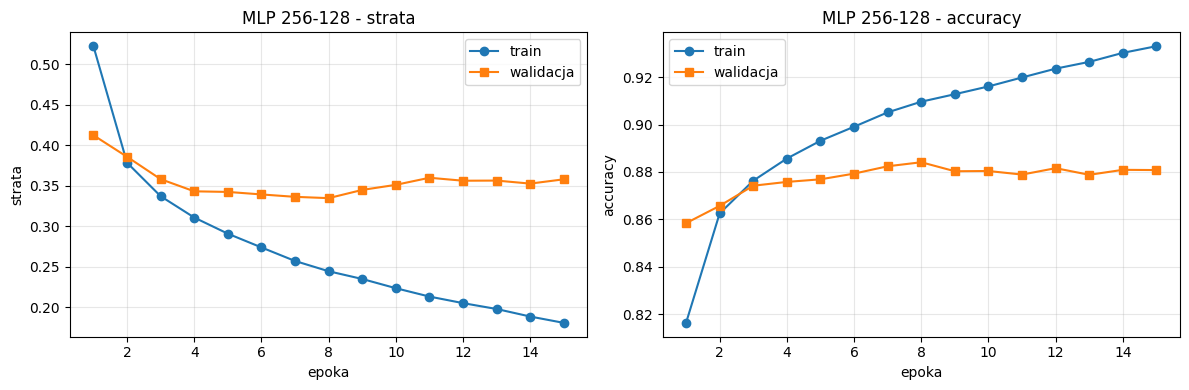

najlepsza val_accuracy: 0.8841 (epoka 8)
test: strata = 0.3846, dokładność = 0.8708
parametry ręcznie: 235,146 | count_params(): 235,146 | zgodne: True


In [8]:
EPOKI_11 = 2 if SZYBKI_TRYB else 15

# 1. Budowa modelu: 784 -> 256 -> 128 -> 10
model_mlp = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="mlp_256_128")
model_mlp.summary()

# 2. Kompilacja i trening
model_mlp.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
t0 = time.time()
hist_mlp = model_mlp.fit(
    x_train, y_train,
    epochs=EPOKI_11,
    batch_size=128,
    validation_data=(x_val, y_val),
    verbose=2,
)
print(f"czas treningu: {time.time() - t0:.1f} s")

# 3. Krzywe uczenia
rysuj_historie(hist_mlp, tytul="MLP 256-128")

# 4. Ocena na zbiorze testowym (raz, na końcu)
test_loss_mlp, test_acc_mlp = model_mlp.evaluate(x_test, y_test, verbose=0)
print(f"najlepsza val_accuracy: {max(hist_mlp.history['val_accuracy']):.4f} "
      f"(epoka {int(np.argmax(hist_mlp.history['val_accuracy'])) + 1})")
print(f"test: strata = {test_loss_mlp:.4f}, dokładność = {test_acc_mlp:.4f}")

# 5. Ręczne liczenie parametrów: n_in * n_out + n_out dla każdej warstwy Dense
param_reczne = (784 * 256 + 256) + (256 * 128 + 128) + (128 * 10 + 10)
print(f"parametry ręcznie: {param_reczne:,} | count_params(): {model_mlp.count_params():,} | "
      f"zgodne: {param_reczne == model_mlp.count_params()}")

### Gdzie model się myli? Macierz pomyłek

Sama dokładność to za mało - chcemy wiedzieć, **które klasy** są mylone. Macierz pomyłek $C$ ma w komórce $C_{ij}$ liczbę próbek o prawdziwej klasie $i$, które model przypisał do klasy $j$. Na przekątnej są poprawne odpowiedzi. (Pełna analiza metryk klasyfikacji: W4 i L5.)

`model.predict(x)` zwraca macierz prawdopodobieństw o kształcie `(n, 10)`; klasę przewidywaną wybieramy przez `argmax` po osi 1.

suma prawdopodobieństw w 1. wierszu: 1.0


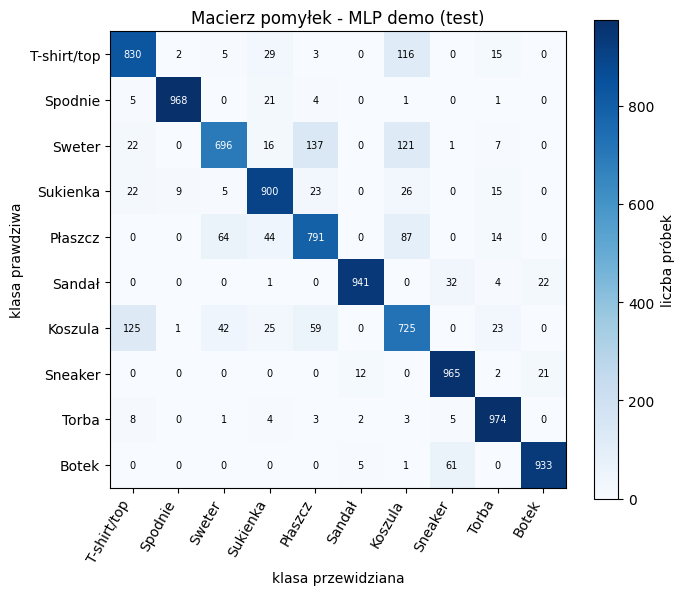

In [9]:
# Demonstracja na model_demo: predykcja i macierz pomyłek
proby = model_demo.predict(x_test, verbose=0)     # (n, 10) prawdopodobieństwa
y_pred_demo = proby.argmax(axis=1)                # klasa o największym prawdopodobieństwie
print("suma prawdopodobieństw w 1. wierszu:", proby[0].sum().round(4))  # softmax -> 1.0

cm = confusion_matrix(y_test, y_pred_demo, labels=range(10))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(NAZWY_KLAS, rotation=60, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(NAZWY_KLAS)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("klasa przewidziana"); ax.set_ylabel("klasa prawdziwa")
ax.set_title("Macierz pomyłek - MLP demo (test)")
plt.colorbar(im, ax=ax, label="liczba próbek"); plt.tight_layout(); plt.show()

### Zadanie 1.2 - Analiza błędów

Dla modelu `model_mlp` z zadania 1.1:

1. Wyznacz predykcje na zbiorze testowym (`y_pred_mlp`).
2. Policz **dokładność dla każdej klasy osobno** (odsetek poprawnych odpowiedzi wśród próbek danej klasy) i przedstaw ją na wykresie słupkowym z nazwami klas.
3. Znajdź **parę klas najczęściej mylonych** (największy element macierzy pomyłek poza przekątną) i wypisz ją.
4. Pokaż 10 błędnie sklasyfikowanych obrazów z podpisem "prawda / predykcja (prawdopodobieństwo)".

**Kryteria sukcesu:** wykres ma tytuł i opisane osie; potrafisz wyjaśnić, dlaczego właśnie te klasy są mylone.

**Wskazówki:** dokładność klasy $k$ to `cm[k, k] / cm[k].sum()`. Żeby znaleźć maksimum poza przekątną, skopiuj macierz i wyzeruj przekątną (`np.fill_diagonal`), potem `np.unravel_index(m.argmax(), m.shape)`.

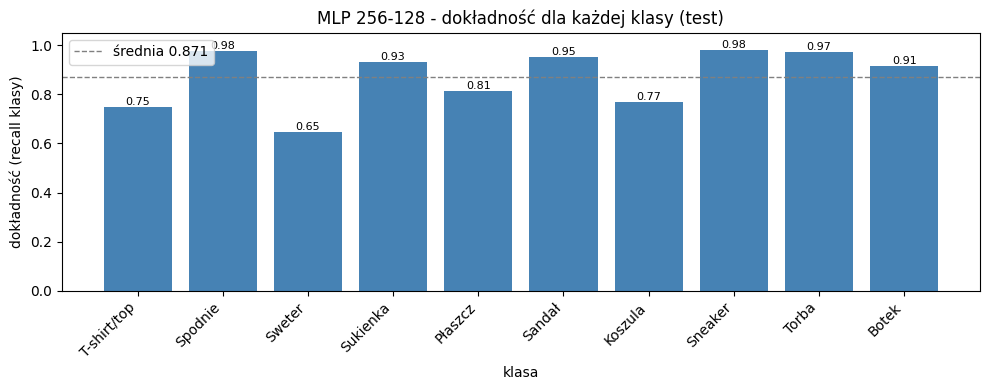

Sweter         0.647
T-shirt/top    0.748
Koszula        0.770
Płaszcz        0.815
Botek          0.914
Sukienka       0.933
Sandał         0.952
Torba          0.972
Spodnie        0.977
Sneaker        0.980

Najczęstsza pomyłka: prawda = T-shirt/top -> predykcja = Koszula (200 razy); w drugą stronę: 75 razy


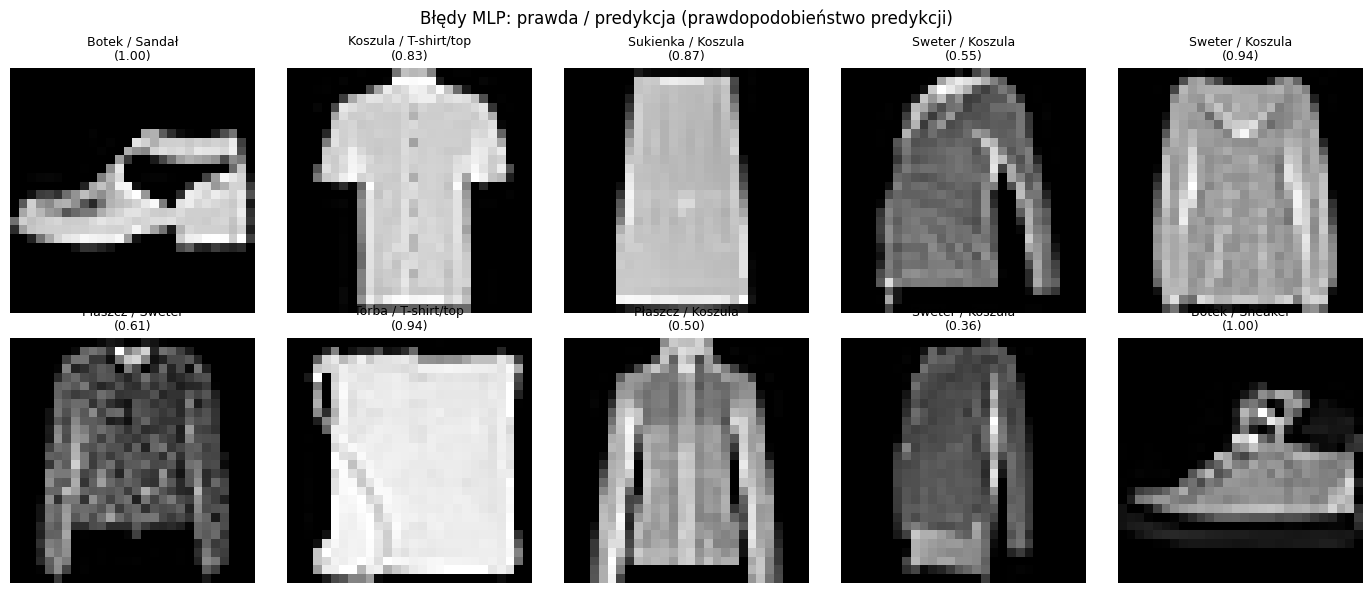

In [10]:
# 1. Predykcje na teście
proby_mlp = model_mlp.predict(x_test, verbose=0)      # (n, 10)
y_pred_mlp = proby_mlp.argmax(axis=1)
cm_mlp = confusion_matrix(y_test, y_pred_mlp, labels=range(10))

# 2. Dokładność dla każdej klasy: poprawne / wszystkie próbki danej klasy (wiersz macierzy)
dokl_klas = cm_mlp.diagonal() / np.maximum(cm_mlp.sum(axis=1), 1)
plt.figure(figsize=(10, 4))
slupki = plt.bar(NAZWY_KLAS, dokl_klas, color="steelblue")
plt.bar_label(slupki, fmt="%.2f", fontsize=8)
plt.axhline(dokl_klas.mean(), color="gray", ls="--", lw=1, label=f"średnia {dokl_klas.mean():.3f}")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1.05)
plt.xlabel("klasa"); plt.ylabel("dokładność (recall klasy)")
plt.title("MLP 256-128 - dokładność dla każdej klasy (test)")
plt.legend(); plt.tight_layout(); plt.show()

print(pd.Series(dokl_klas, index=NAZWY_KLAS).sort_values().round(3).to_string())

# 3. Najczęściej mylona para: maksimum macierzy pomyłek poza przekątną
m = cm_mlp.copy()
np.fill_diagonal(m, 0)
i, j = np.unravel_index(m.argmax(), m.shape)
print(f"\nNajczęstsza pomyłka: prawda = {NAZWY_KLAS[i]} -> predykcja = {NAZWY_KLAS[j]} "
      f"({m[i, j]} razy); w drugą stronę: {m[j, i]} razy")

# 4. Dziesięć błędnie sklasyfikowanych obrazów
bledne = np.where(y_pred_mlp != y_test)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx in zip(axes.flat, bledne):
    ax.imshow(x_test[idx], cmap="gray")
    ax.set_title(f"{NAZWY_KLAS[y_test[idx]]} / {NAZWY_KLAS[y_pred_mlp[idx]]}\n"
                 f"({proby_mlp[idx, y_pred_mlp[idx]]:.2f})", fontsize=9)
    ax.axis("off")
plt.suptitle("Błędy MLP: prawda / predykcja (prawdopodobieństwo predykcji)")
plt.tight_layout(); plt.show()

## 2. Regresja: California Housing

### Zbiór danych
Dane ze spisu powszechnego w Kalifornii (1990): 20 640 dzielnic, 8 cech numerycznych (mediana dochodu, wiek budynków, średnia liczba pokoi, populacja, położenie geograficzne...). Cel: **mediana wartości domu** w dzielnicy, w setkach tysięcy dolarów.

### Co zmienia się względem klasyfikacji?
- warstwa wyjściowa: **1 neuron bez aktywacji** (aktywacja liniowa) - wyjście może być dowolną liczbą rzeczywistą,
- funkcja straty: **MSE** $= \frac{1}{n}\sum_i (y_i - \hat y_i)^2$ lub **MAE** $= \frac{1}{n}\sum_i |y_i - \hat y_i|$ (W3),
- metryki: MAE (w jednostkach celu, łatwa interpretacja), RMSE $= \sqrt{\text{MSE}}$, ewentualnie $R^2$.

MSE silniej karze duże błędy (kwadrat), MAE jest bardziej odporne na wartości odstające. Często trenujemy na MSE (gładki gradient), a raportujemy MAE.

In [11]:
dane = fetch_california_housing(as_frame=True)
df = dane.frame
if SZYBKI_TRYB:
    df = df.iloc[:2000]
print(df.shape)
df.describe().T.round(2)

(20640, 9)


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


### Standaryzacja - tylko na zbiorze treningowym!

Cechy mają bardzo różne skale (populacja - tysiące, mediana dochodu - kilka jednostek). Gradient względem wag przy cechach o dużej skali byłby ogromny, a przy małej - znikomy; trening byłby niestabilny. Dlatego standaryzujemy:

$$x' = \frac{x - \mu_{train}}{\sigma_{train}}.$$

**Kluczowe:** średnią $\mu$ i odchylenie $\sigma$ liczymy **wyłącznie na zbiorze treningowym**, a potem tymi samymi wartościami przekształcamy walidację i test. Gdybyśmy dopasowali `StandardScaler` do całych danych, informacja ze zbioru testowego "przeciekłaby" do treningu (**data leakage**, W4) - wynik testowy byłby zbyt optymistyczny. W praktyce produkcyjnej nowe dane też przekształcamy parametrami z treningu, bo przyszłości nie znamy.

Schemat: `scaler.fit(X_train)` -> `scaler.transform(X_train / X_val / X_test)`.

In [12]:
X = df[dane.feature_names].values.astype("float32")
y = df["MedHouseVal"].values.astype("float32")

# Podział 60 / 20 / 20: najpierw odcinamy test, potem z reszty walidację
X_tmp, X_te_r, y_tmp, y_te_r = train_test_split(X, y, test_size=0.2, random_state=SEED)
X_tr_r, X_va_r, y_tr_r, y_va_r = train_test_split(X_tmp, y_tmp, test_size=0.25, random_state=SEED)

scaler = StandardScaler().fit(X_tr_r)       # fit TYLKO na train
X_tr_s = scaler.transform(X_tr_r)           # transform na wszystkich podzbiorach
X_va_s = scaler.transform(X_va_r)
X_te_s = scaler.transform(X_te_r)

print("train/val/test:", X_tr_s.shape, X_va_s.shape, X_te_s.shape)
print("średnie cech po standaryzacji (train):", X_tr_s.mean(axis=0).round(3))
print("średnie cech po standaryzacji (test): ", X_te_s.mean(axis=0).round(3), "<- nie muszą być 0")

train/val/test: (12384, 8) (4128, 8) (4128, 8)
średnie cech po standaryzacji (train): [ 0.  0. -0.  0. -0.  0.  0.  0.]
średnie cech po standaryzacji (test):  [-0.021  0.014 -0.004  0.011 -0.005 -0.01  -0.026  0.03 ] <- nie muszą być 0


### Baseline - zawsze zaczynaj od punktu odniesienia

Zanim powiesz, że sieć "działa dobrze", porównaj ją z czymś prostym. Najprostszy baseline w regresji: **zawsze przewiduj średnią z treningu**. Jeśli sieć nie jest wyraźnie lepsza, coś jest nie tak (dane, skalowanie, architektura).

In [13]:
# Baseline 0: stała predykcja = średnia celu na zbiorze treningowym
pred_sr = np.full_like(y_te_r, y_tr_r.mean())
mae_sr = mean_absolute_error(y_te_r, pred_sr)
rmse_sr = np.sqrt(mean_squared_error(y_te_r, pred_sr))
print(f"Baseline (średnia): MAE = {mae_sr:.3f}, RMSE = {rmse_sr:.3f}  (jednostka: 100 tys. $)")

Baseline (średnia): MAE = 0.905, RMSE = 1.145  (jednostka: 100 tys. $)


### Zadanie 2.1 - Baseline liniowy

Mocniejszym punktem odniesienia jest **regresja liniowa** (klasyczny model ML, W1).

1. Dopasuj `LinearRegression` ze `sklearn` do `(X_tr_s, y_tr_r)`.
2. Policz MAE i RMSE na zbiorze **testowym**; zapisz w zmiennych `mae_lin`, `rmse_lin`.
3. Wypisz porównanie z baseline'em średniej.

**Kryteria sukcesu (pełny tryb):** MAE regresji liniowej ok. 0.53, wyraźnie mniej niż baseline średniej (ok. 0.9).

In [14]:
# Regresja liniowa na tych samych (wystandaryzowanych) cechach
lin = LinearRegression().fit(X_tr_s, y_tr_r)
pred_lin = lin.predict(X_te_s)

mae_lin = mean_absolute_error(y_te_r, pred_lin)
rmse_lin = np.sqrt(mean_squared_error(y_te_r, pred_lin))

print(f"Baseline (średnia)  : MAE = {mae_sr:.3f}, RMSE = {rmse_sr:.3f}")
print(f"Regresja liniowa    : MAE = {mae_lin:.3f}, RMSE = {rmse_lin:.3f}")
print(f"Poprawa MAE względem średniej: {100 * (1 - mae_lin / mae_sr):.1f}%")

Baseline (średnia)  : MAE = 0.905, RMSE = 1.145
Regresja liniowa    : MAE = 0.533, RMSE = 0.750
Poprawa MAE względem średniej: 41.1%


### Zadanie 2.2 - Sieć do regresji

1. Zbuduj `model_reg`: `Input(8) -> Dense(64, relu) -> Dense(64, relu) -> Dense(1)` (bez aktywacji na wyjściu!).
2. Skompiluj z Adam (lr = 1e-3), stratą `"mse"` i metryką `"mae"`.
3. Wytrenuj `EPOKI_22` epok, `batch_size=64`, z walidacją `(X_va_s, y_va_r)`. Narysuj krzywe (`metryka="mae"`).
4. Policz MAE i RMSE na teście (`mae_nn`, `rmse_nn`) i zestaw w tabeli (pandas DataFrame) z baseline'ami.
5. Narysuj wykres rozrzutu: wartości prawdziwe vs przewidziane na teście, z linią $y = x$.

**Kryteria sukcesu (pełny tryb):** MAE sieci < 0.42 (wyraźnie lepiej niż liniowa).

**Wskazówki:** `model_reg.predict(X_te_s).ravel()` - wyjście ma kształt `(n, 1)`, spłaszczamy je do `(n,)`. Zapomnienie o `ravel()` przy liczeniu `y - y_pred` daje broadcasting do macierzy `(n, n)` - klasyczny, cichy błąd!

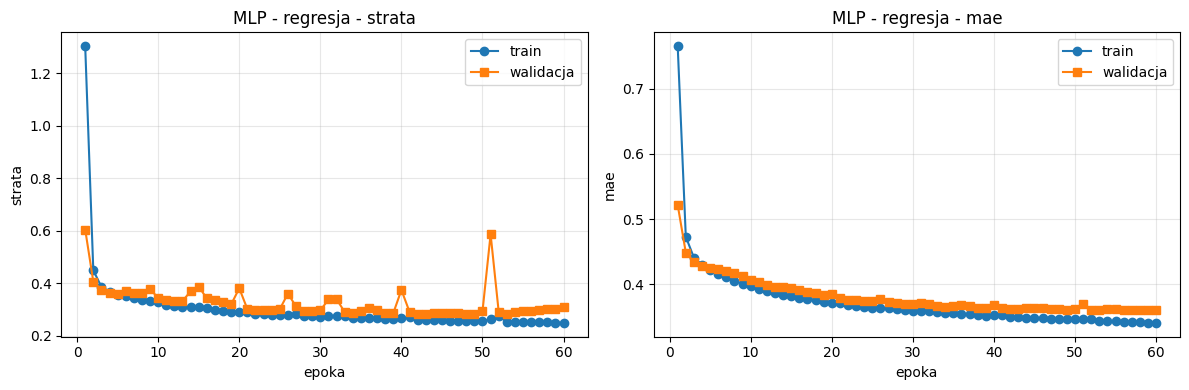

,MAE,RMSE
średnia (baseline),0.905,1.145
regresja liniowa,0.533,0.750
MLP 64-64,0.360,0.533


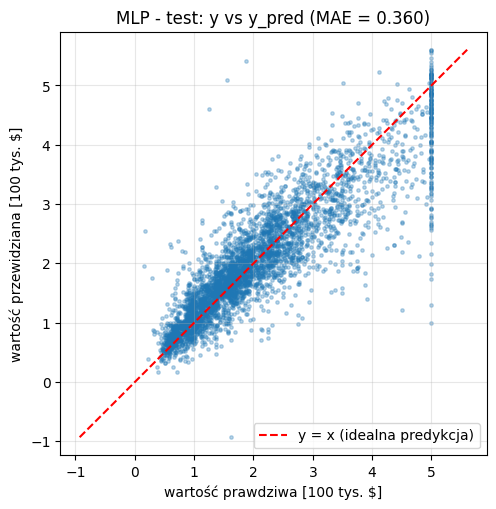

In [15]:
EPOKI_22 = 3 if SZYBKI_TRYB else 60

# 1. Model: 8 cech -> 64 -> 64 -> 1 (wyjście liniowe, bez aktywacji)
keras.utils.set_random_seed(SEED)
model_reg = keras.Sequential([
    keras.Input(shape=(X_tr_s.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1),
], name="mlp_regresja")

# 2. Kompilacja: trenujemy na MSE, raportujemy MAE
model_reg.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])

# 3. Trening i krzywe uczenia
hist_reg = model_reg.fit(X_tr_s, y_tr_r, epochs=EPOKI_22, batch_size=64,
                         validation_data=(X_va_s, y_va_r), verbose=0)
rysuj_historie(hist_reg, metryka="mae", tytul="MLP - regresja")

# 4. Ocena na teście; ravel() spłaszcza (n, 1) -> (n,)
pred_nn = model_reg.predict(X_te_s, verbose=0).ravel()
mae_nn = mean_absolute_error(y_te_r, pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_te_r, pred_nn))

tabela_reg = pd.DataFrame({
    "MAE": [mae_sr, mae_lin, mae_nn],
    "RMSE": [rmse_sr, rmse_lin, rmse_nn],
}, index=["średnia (baseline)", "regresja liniowa", "MLP 64-64"]).round(3)
display(tabela_reg)

# 5. Wartości prawdziwe vs przewidziane
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_te_r, pred_nn, s=6, alpha=0.3)
granice = [min(y_te_r.min(), pred_nn.min()), max(y_te_r.max(), pred_nn.max())]
plt.plot(granice, granice, "r--", lw=1.5, label="y = x (idealna predykcja)")
plt.xlabel("wartość prawdziwa [100 tys. $]"); plt.ylabel("wartość przewidziana [100 tys. $]")
plt.title(f"MLP - test: y vs y_pred (MAE = {mae_nn:.3f})")
plt.legend(); plt.grid(alpha=0.3); plt.axis("equal"); plt.show()
# Pionowy "pas" przy y = 5.0: ceny w zbiorze są obcięte (cenzurowane) na 500 tys. $,
# więc model nie ma jak nauczyć się wyższych wartości i je zaniża.

## 3. Callbacki - automatyzacja treningu

**Callback** to obiekt, którego metody Keras wywołuje w określonych momentach treningu (początek/koniec epoki, batcha, treningu). Najważniejsze wbudowane:

| Callback | Co robi | Kluczowe argumenty |
|---|---|---|
| `EarlyStopping` | przerywa trening, gdy monitorowana metryka przestaje się poprawiać | `monitor="val_loss"`, `patience`, `restore_best_weights=True` |
| `ModelCheckpoint` | zapisuje model (lub wagi) na dysk, np. tylko gdy jest najlepszy | `filepath` (`.keras` lub `.weights.h5`), `save_best_only=True` |
| `ReduceLROnPlateau` | zmniejsza learning rate, gdy metryka stoi w miejscu | `factor` (np. 0.5), `patience`, `min_lr` |

**Early stopping jako regularyzacja (W3):** zatrzymując trening w minimum `val_loss`, nie pozwalamy sieci "zapamiętać" szumu ze zbioru treningowego. `patience` mówi, ile epok bez poprawy tolerujemy (krzywa walidacyjna jest zaszumiona, więc 1 epoka to za mało). `restore_best_weights=True` przywraca wagi z najlepszej epoki - bez tego zostałyby wagi z ostatniej (gorszej) epoki.

**ReduceLROnPlateau - intuicja:** na początku duży krok pozwala szybko zejść w dół funkcji straty; blisko minimum duży krok "przeskakuje" dolinę, więc krok zmniejszamy.

Epoch 11: early stopping
Restoring model weights from the end of the best epoch: 8.
Wykonano 11 z 50 epok; najlepsza epoka (min val_loss): 8


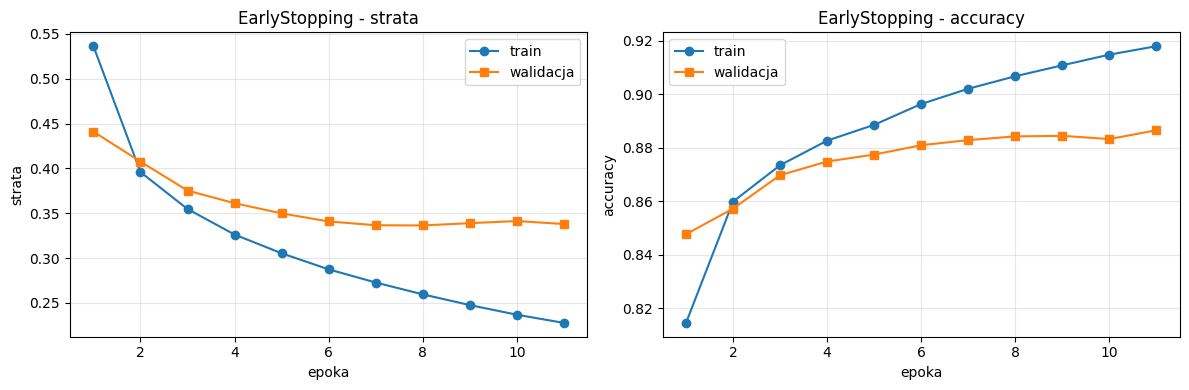

In [16]:
# Demonstracja: EarlyStopping na klasyfikacji Fashion-MNIST z dużą maksymalną liczbą epok
EPOKI_MAX_DEMO = 3 if SZYBKI_TRYB else 50

wczesne_zatrzymanie = keras.callbacks.EarlyStopping(
    monitor="val_loss",          # obserwujemy stratę walidacyjną
    patience=3,                  # 3 epoki bez poprawy -> stop
    restore_best_weights=True,   # przywróć wagi z najlepszej epoki
    verbose=1,
)

model_es = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(256, activation="relu"),
                             layers.Dense(10, activation="softmax")])
model_es.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_es = model_es.fit(x_train, y_train, epochs=EPOKI_MAX_DEMO, batch_size=128,
                       validation_data=(x_val, y_val), callbacks=[wczesne_zatrzymanie], verbose=0)

n_epok = len(hist_es.history["loss"])
najlepsza = int(np.argmin(hist_es.history["val_loss"])) + 1
print(f"Wykonano {n_epok} z {EPOKI_MAX_DEMO} epok; najlepsza epoka (min val_loss): {najlepsza}")
rysuj_historie(hist_es, tytul="EarlyStopping")

### Zadanie 3.1 - Trzy callbacki naraz (regresja)

Wytrenuj **nowy** model o architekturze jak w zad. 2.2 (`model_cb`) na danych California Housing, z maksymalną liczbą epok `EPOKI_MAX_31` i trzema callbackami:

- `EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)`,
- `ModelCheckpoint("najlepszy_reg.keras", monitor="val_loss", save_best_only=True)`,
- `ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)`.

Następnie:
1. wypisz, po ilu epokach trening się zatrzymał i która epoka była najlepsza,
2. narysuj, jak zmieniał się learning rate w kolejnych epokach (Keras zapisuje go w `historia.history["learning_rate"]`),
3. wczytaj model z pliku `najlepszy_reg.keras` i policz jego MAE na teście.

**Kryteria sukcesu:** plik `najlepszy_reg.keras` istnieje; w pełnym trybie trening kończy się przed limitem epok, a lr zmalał co najmniej raz; MAE testowe wczytanego modelu <= MAE z zadania 2.2 (lub bardzo zbliżone).

**Wskazówka:** callbacki przekazujemy jako listę: `fit(..., callbacks=[cb1, cb2, cb3])`.


Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.

Epoch 37: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 42: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 48: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 57: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.

Epoch 63: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.

Epoch 69: ReduceLROnPlateau reducing learning rate to 1e-05.
Epoch 75: early stopping
Restoring model weights from the end of the best epoch: 65.
Trening zatrzymał się po 75 z 200 epok; minimum val_loss w epoce 75 (val_loss = 0.2891)
EarlyStopping przywrócił wagi z epoki 65


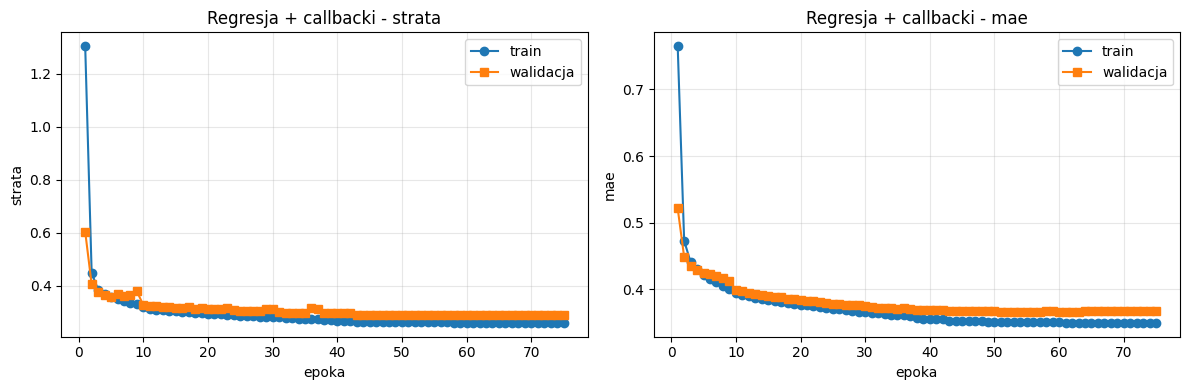

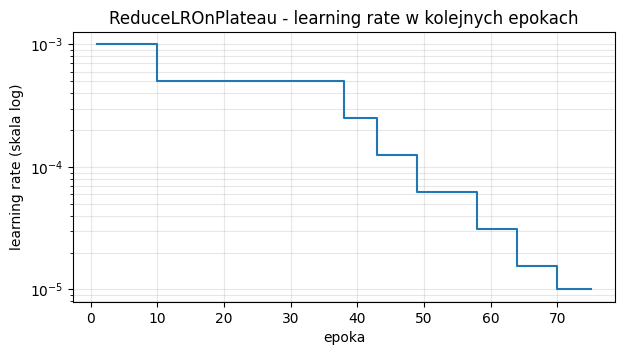

liczba zmniejszeń lr: 7 | końcowy lr: 9.999999747378752e-06
plik istnieje: True
MAE test - najlepszy model z pliku: 0.367 | model z zad. 2.2: 0.360


In [17]:
EPOKI_MAX_31 = 3 if SZYBKI_TRYB else 200

keras.utils.set_random_seed(SEED)
model_cb = keras.Sequential([
    keras.Input(shape=(X_tr_s.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(1),
], name="mlp_regresja_callbacki")
model_cb.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])

# min_delta: poprawa mniejsza niż 1e-4 nie liczy się jako poprawa. Bez tego, przy coraz mniejszym lr,
# val_loss spada o ułamki promila co kilka epok i EarlyStopping nigdy się nie uruchamia (sprawdzone: 200/200 epok).
callbacki = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True,
                                  min_delta=1e-4, verbose=1),
    keras.callbacks.ModelCheckpoint("najlepszy_reg.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5, verbose=1),
]
hist_cb = model_cb.fit(X_tr_s, y_tr_r, epochs=EPOKI_MAX_31, batch_size=64,
                       validation_data=(X_va_s, y_va_r), callbacks=callbacki, verbose=0)

# 1. Liczba epok i najlepsza epoka
n_epok_cb = len(hist_cb.history["loss"])
najlepsza_cb = int(np.argmin(hist_cb.history["val_loss"])) + 1
print(f"Trening zatrzymał się po {n_epok_cb} z {EPOKI_MAX_31} epok; "
      f"minimum val_loss w epoce {najlepsza_cb} (val_loss = {min(hist_cb.history['val_loss']):.4f})")
# EarlyStopping (z min_delta) za "najlepszą" uznaje ostatnią epokę z poprawą >= 1e-4 - to jej wagi przywraca;
# ModelCheckpoint nie ma min_delta, więc w pliku jest model z epoki z absolutnym minimum val_loss.
print(f"EarlyStopping przywrócił wagi z epoki {callbacki[0].best_epoch + 1}")
rysuj_historie(hist_cb, metryka="mae", tytul="Regresja + callbacki")

# 2. Przebieg learning rate (zapisuje go ReduceLROnPlateau)
lr_hist = hist_cb.history.get("learning_rate")
if lr_hist is not None:
    plt.figure(figsize=(7, 3.5))
    plt.step(np.arange(1, len(lr_hist) + 1), lr_hist, where="post")
    plt.yscale("log")
    plt.xlabel("epoka"); plt.ylabel("learning rate (skala log)")
    plt.title("ReduceLROnPlateau - learning rate w kolejnych epokach")
    plt.grid(alpha=0.3, which="both"); plt.show()
    print("liczba zmniejszeń lr:", int(np.sum(np.diff(lr_hist) < 0)), "| końcowy lr:", lr_hist[-1])

# 3. Wczytanie najlepszego modelu z pliku i MAE na teście
print("plik istnieje:", os.path.exists("najlepszy_reg.keras"))
model_best = keras.models.load_model("najlepszy_reg.keras")
pred_best = model_best.predict(X_te_s, verbose=0).ravel()
mae_best = mean_absolute_error(y_te_r, pred_best)
print(f"MAE test - najlepszy model z pliku: {mae_best:.3f} | model z zad. 2.2: {mae_nn:.3f}")

---
## Przerwa (10 min)
---

## 4. Optymalizatory i learning rate

Przypomnienie z W3 (wzory dla jednego parametru $w$, gradient $g_t = \nabla_w L$, learning rate $\eta$):

- **SGD:** $w \leftarrow w - \eta\, g_t$. Prosty, ale wolny w "wąskich dolinach" funkcji straty.
- **SGD z momentum:** $v \leftarrow \beta v - \eta g_t,\; w \leftarrow w + v$ (typowo $\beta = 0.9$). Jak kulka toczona po zboczu - "rozpęd" wygładza oscylacje i przyspiesza ruch w spójnym kierunku.
- **RMSprop:** $s \leftarrow \rho s + (1-\rho) g_t^2,\; w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon} g_t$. Każdy parametr ma własny, adaptacyjny krok - duże gradienty są tłumione.
- **Adam:** łączy momentum (średnia gradientów $m$) i RMSprop (średnia kwadratów $v$) z korekcją obciążenia: $w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}$. Bardzo dobry wybór domyślny (lr = 1e-3).

**Learning rate** to zwykle najważniejszy hiperparametr. Za mały - trening bardzo wolny; za duży - strata oscyluje lub rośnie (rozbieżność, jak w L1).

Do porównań użyjemy funkcji, która za każdym razem buduje **identyczny** model od nowa (te same seedy), zmieniając tylko optymalizator - wtedy porównanie jest uczciwe.

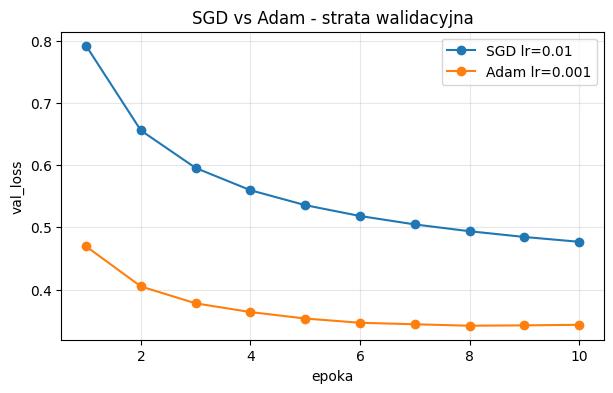

In [18]:
EPOKI_OPT = 2 if SZYBKI_TRYB else 10

def zbuduj_mlp_fashion():
    # Ten sam MLP za każdym razem; seed gwarantuje identyczną inicjalizację wag
    keras.utils.set_random_seed(SEED)
    return keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten(),
                             layers.Dense(128, activation="relu"),
                             layers.Dense(10, activation="softmax")])

def trenuj_z_optymalizatorem(optymalizator, epoki=EPOKI_OPT):
    # Trenuje świeży model z podanym optymalizatorem i zwraca słownik historii
    model = zbuduj_mlp_fashion()
    model.compile(optimizer=optymalizator, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = model.fit(x_train, y_train, epochs=epoki, batch_size=128,
                  validation_data=(x_val, y_val), verbose=0)
    return h.history

# Demonstracja: zwykły SGD vs Adam
wyniki_demo = {
    "SGD lr=0.01": trenuj_z_optymalizatorem(keras.optimizers.SGD(learning_rate=0.01)),
    "Adam lr=0.001": trenuj_z_optymalizatorem(keras.optimizers.Adam(learning_rate=0.001)),
}
plt.figure(figsize=(7, 4))
for nazwa, h in wyniki_demo.items():
    plt.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], "o-", label=nazwa)
plt.xlabel("epoka"); plt.ylabel("val_loss"); plt.title("SGD vs Adam - strata walidacyjna")
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Zadanie 4.1 - Porównanie czterech optymalizatorów

Używając `trenuj_z_optymalizatorem`, porównaj:
- `SGD(learning_rate=0.01)`,
- `SGD(learning_rate=0.01, momentum=0.9)`,
- `RMSprop(learning_rate=0.001)`,
- `Adam(learning_rate=0.001)`.

1. Zapisz historie w słowniku `wyniki_opt` (klucz = nazwa).
2. Narysuj na **jednym** wykresie `val_loss` wszystkich wariantów, a na drugim `val_accuracy`.
3. Utwórz tabelę (DataFrame) z najlepszą `val_accuracy` i epoką, w której ją osiągnięto.

**Kryteria sukcesu:** SGD bez momentum powinien być wyraźnie najwolniejszy; potrafisz to wyjaśnić na podstawie wzorów powyżej.

**Uwaga:** optymalizator to obiekt ze stanem (np. bufor momentum) - dla każdego modelu twórz **nową** instancję, nie używaj tej samej dwa razy.

SGD lr=0.01        gotowe w 16.1 s
SGD+momentum 0.9   gotowe w 18.0 s
RMSprop lr=0.001   gotowe w 16.5 s
Adam lr=0.001      gotowe w 16.7 s


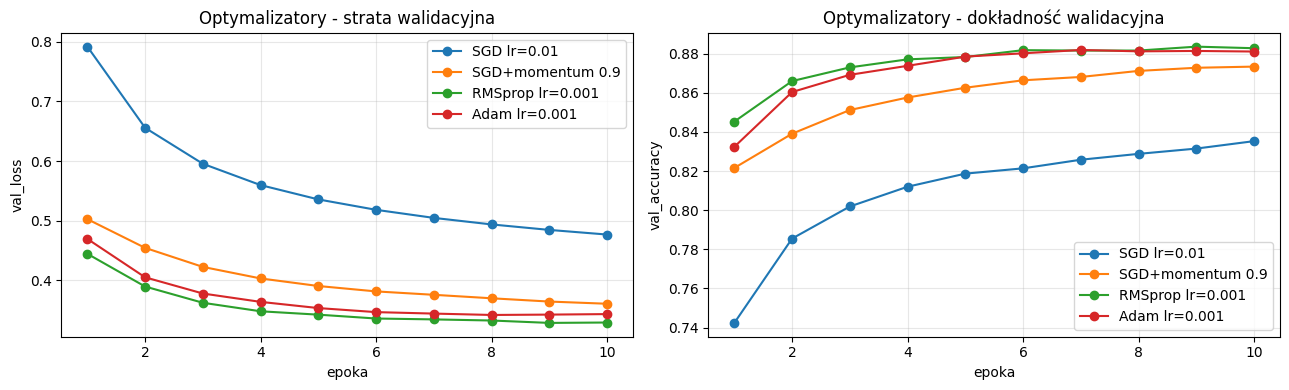

,najlepsza val_accuracy,epoka,val_loss (ostatnia epoka)
RMSprop lr=0.001,0.8836,9,0.3292
Adam lr=0.001,0.8819,7,0.3433
SGD+momentum 0.9,0.8734,10,0.3607
SGD lr=0.01,0.8353,10,0.4767


In [27]:
# Każdy wariant dostaje NOWĄ instancję optymalizatora (optymalizator ma stan, np. bufor momentum)
optymalizatory = {
    "SGD lr=0.01": lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD+momentum 0.9": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop lr=0.001": lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam lr=0.001": lambda: keras.optimizers.Adam(learning_rate=0.001),
}

# 1. Historie w słowniku
wyniki_opt = {}
for nazwa, utworz in optymalizatory.items():
    t0 = time.time()
    wyniki_opt[nazwa] = trenuj_z_optymalizatorem(utworz())
    print(f"{nazwa:18s} gotowe w {time.time() - t0:.1f} s")

# 2. Dwa wykresy: val_loss i val_accuracy
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nazwa, h in wyniki_opt.items():
    ep = np.arange(1, len(h["val_loss"]) + 1)
    ax[0].plot(ep, h["val_loss"], "o-", label=nazwa)
    ax[1].plot(ep, h["val_accuracy"], "o-", label=nazwa)
ax[0].set_title("Optymalizatory - strata walidacyjna"); ax[0].set_ylabel("val_loss")
ax[1].set_title("Optymalizatory - dokładność walidacyjna"); ax[1].set_ylabel("val_accuracy")
for a in ax:
    a.set_xlabel("epoka"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# 3. Tabela: najlepsza val_accuracy i epoka
tabela_opt = pd.DataFrame({
    "najlepsza val_accuracy": [max(h["val_accuracy"]) for h in wyniki_opt.values()],
    "epoka": [int(np.argmax(h["val_accuracy"])) + 1 for h in wyniki_opt.values()],
    "val_loss (ostatnia epoka)": [h["val_loss"][-1] for h in wyniki_opt.values()],
}, index=list(wyniki_opt.keys())).round(4)
display(tabela_opt.sort_values("najlepsza val_accuracy", ascending=False))

### Zadanie 4.2 - Wpływ learning rate

Dla optymalizatora Adam sprawdź learning rate z listy `[1e-4, 1e-3, 1e-2, 1e-1]`.

1. Narysuj krzywe `loss` (treningowej!) dla wszystkich wartości na jednym wykresie.
2. Opisz w komórce markdown (2-3 zdania): który lr jest za mały, który za duży i po czym to widać.

**Kryteria sukcesu:** dla lr = 0.1 widać wyraźnie gorszą (wyższą, niestabilną) stratę, dla 1e-4 - powolny spadek.

**Wskazówka:** jeśli strata dla dużego lr robi się `nan`, to też jest wynik - zapisz to w wnioskach (rozbieżność).

Adam lr=0.0001: loss 1.002 -> 0.392, najlepsza val_accuracy 0.856, nan w stracie: False
Adam lr=0.001: loss 0.573 -> 0.264, najlepsza val_accuracy 0.882, nan w stracie: False
Adam lr=0.01: loss 0.550 -> 0.304, najlepsza val_accuracy 0.870, nan w stracie: False
Adam lr=0.1: loss 2.088 -> 1.211, najlepsza val_accuracy 0.618, nan w stracie: False


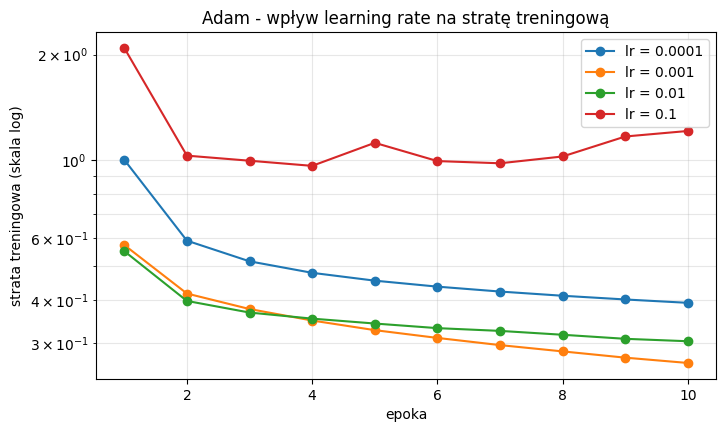

In [20]:
lista_lr = [1e-4, 1e-3, 1e-2, 1e-1]
wyniki_lr = {}
for lr in lista_lr:
    wyniki_lr[lr] = trenuj_z_optymalizatorem(keras.optimizers.Adam(learning_rate=lr))
    h = wyniki_lr[lr]
    print(f"Adam lr={lr:g}: loss {h['loss'][0]:.3f} -> {h['loss'][-1]:.3f}, "
          f"najlepsza val_accuracy {np.nanmax(h['val_accuracy']):.3f}, "
          f"nan w stracie: {bool(np.isnan(h['loss']).any())}")

# Strata TRENINGOWA dla każdego lr na jednym wykresie
plt.figure(figsize=(8, 4.5))
for lr, h in wyniki_lr.items():
    plt.plot(np.arange(1, len(h["loss"]) + 1), h["loss"], "o-", label=f"lr = {lr:g}")
plt.yscale("log")
plt.xlabel("epoka"); plt.ylabel("strata treningowa (skala log)")
plt.title("Adam - wpływ learning rate na stratę treningową")
plt.legend(); plt.grid(alpha=0.3, which="both"); plt.show()

*Twoje wnioski (zad. 4.2):* Wyniki z uruchomienia w Colab (GPU T4, pełny tryb, 10 epok). **lr = 1e-4 jest za mały:** strata treningowa spada powoli i równo (1.00 -> 0.39); po 10 epokach jest wyraźnie wyżej niż dla 1e-3 (0.26), a val_accuracy to tylko 0.856. **lr = 1e-3 jest najlepszy** (najniższa strata, val_accuracy 0.882). **lr = 1e-2** szybko startuje, ale kończy wyżej (0.30) i krzywa jest bardziej poszarpana - krok zaczyna przeskakiwać dno doliny. **lr = 0.1 jest za duży:** strata po 1. epoce ~2.09, czyli blisko log(10) = 2.30 (poziom losowego zgadywania), kończy na 1.21, a val_accuracy to 0.618. Nie dostaliśmy `nan`, ale trening jest niestabilny i daleko od minimum.

## 5. Celowe przeuczenie i jego "leczenie"

### Przeuczenie (overfitting)
Model o dużej pojemności (dużo parametrów) trenowany na małym zbiorze potrafi "zapamiętać" dane treningowe łącznie z szumem. Objaw: strata treningowa spada niemal do zera, a walidacyjna po pewnym czasie **rośnie**. Żeby wyraźnie to zobaczyć, celowo:
- zmniejszymy zbiór treningowy (do 1000 obrazów),
- użyjemy dużej sieci (3 x 512 neuronów, ok. 930 tys. parametrów),
- będziemy trenować długo.

### Metody regularyzacji (W2, W3)
- **Dropout($p$):** w trakcie treningu każdy neuron jest losowo "wyłączany" z prawdopodobieństwem $p$ (pozostałe są skalowane przez $1/(1-p)$). Sieć nie może polegać na pojedynczych neuronach - uczy się reprezentacji redundantnych. Działa jak uśrednianie wielu "podsieci". W predykcji Dropout jest wyłączony.
- **L2 (weight decay):** do straty dodajemy karę $\lambda \sum w^2$. Gradient kary $2\lambda w$ ściąga wagi w stronę zera - preferowane są "gładsze" funkcje. W Keras: `kernel_regularizer=keras.regularizers.l2(lambda)`.
- **BatchNormalization:** normalizuje aktywacje w mini-batchu do średniej 0 i wariancji 1, potem skaluje uczonymi parametrami $\gamma, \beta$:
  $\hat{x} = \frac{x - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}},\; y = \gamma \hat{x} + \beta$.
  Głównie **stabilizuje i przyspiesza** trening (pozwala na większy lr); efekt regularyzujący jest uboczny (szum statystyk batcha) i słabszy niż Dropout.
- **Early stopping** - poznaliśmy w sekcji 3.

parametry: 932362


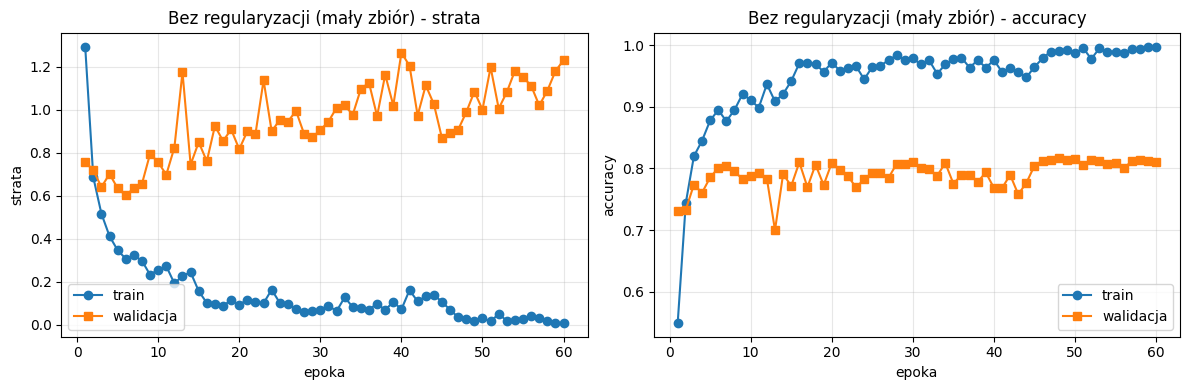

train acc: 0.998, val acc: 0.810, min val_loss w epoce 6


In [21]:
# Mały zbiór treningowy - ułatwia przeuczenie
N_MALY = 500 if SZYBKI_TRYB else 1000
x_maly, y_maly = x_train[:N_MALY], y_train[:N_MALY]
EPOKI_REG = 3 if SZYBKI_TRYB else 60

def zbuduj_przeuczony():
    # Duży MLP bez regularyzacji: 784 -> 512 -> 512 -> 512 -> 10
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()])
    for _ in range(3):
        model.add(layers.Dense(512, activation="relu"))
    model.add(layers.Dense(10, activation="softmax"))
    return model

def trenuj_reg(model, epoki=EPOKI_REG):
    # Wspólna procedura treningu dla wszystkich wariantów regularyzacji
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(x_maly, y_maly, epochs=epoki, batch_size=64,
                     validation_data=(x_val, y_val), verbose=0).history

model_over = zbuduj_przeuczony()
print("parametry:", model_over.count_params())
h_over = trenuj_reg(model_over)
rysuj_historie(h_over, tytul="Bez regularyzacji (mały zbiór)")
print(f"train acc: {h_over['accuracy'][-1]:.3f}, val acc: {h_over['val_accuracy'][-1]:.3f}, "
      f"min val_loss w epoce {int(np.argmin(h_over['val_loss'])) + 1}")

### Zadanie 5.1 - Dropout i L2

Napisz funkcję `zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False)`, która buduje taką samą architekturę jak `zbuduj_przeuczony`, ale:
- jeśli `l2 > 0`, każda warstwa ukryta `Dense` ma `kernel_regularizer=keras.regularizers.l2(l2)`,
- jeśli `batchnorm=True`, po każdej warstwie `Dense(512)` (bez aktywacji) dodaj `BatchNormalization()`, a następnie `Activation("relu")`,
- jeśli `dropout > 0`, po każdej warstwie ukrytej (po aktywacji) dodaj `Dropout(dropout)`.

Następnie wytrenuj funkcją `trenuj_reg` dwa warianty i zapisz historie:
- `h_drop` - Dropout 0.5,
- `h_l2` - L2 z $\lambda = 10^{-3}$.

**Kryteria sukcesu (pełny tryb):** dla obu wariantów rosnąca część `val_loss` jest wyraźnie mniejsza niż bez regularyzacji, a różnica między train i val accuracy maleje.

**Wskazówki:** pamiętaj o `keras.utils.set_random_seed(SEED)` na początku funkcji (uczciwe porównanie). Kolejność `Dense -> BatchNorm -> ReLU -> Dropout` to popularny wybór; w literaturze spotyka się też BN po aktywacji.

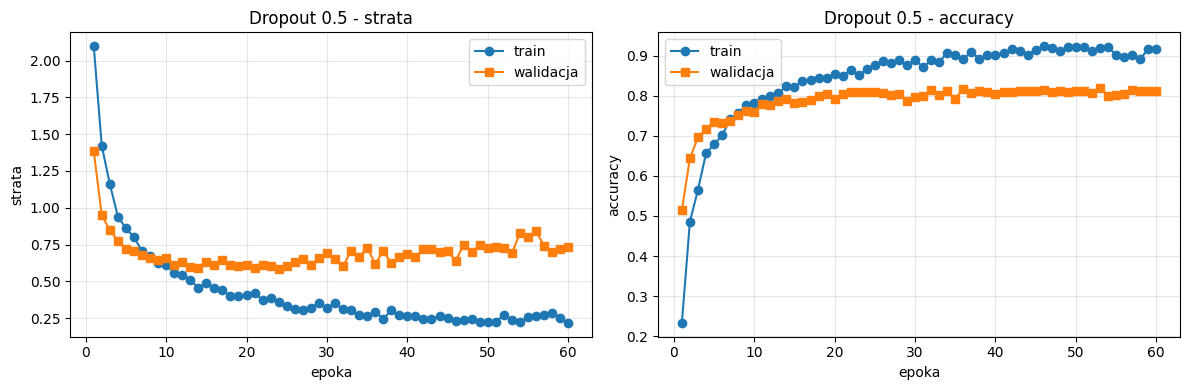

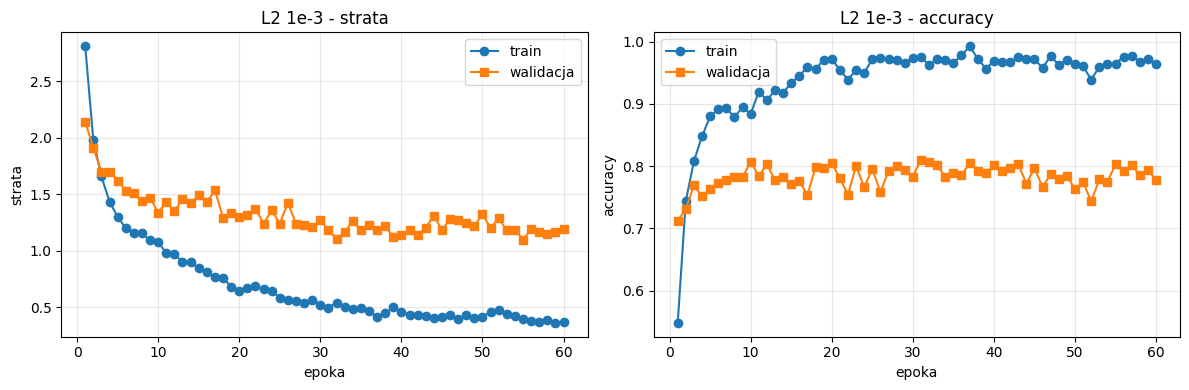

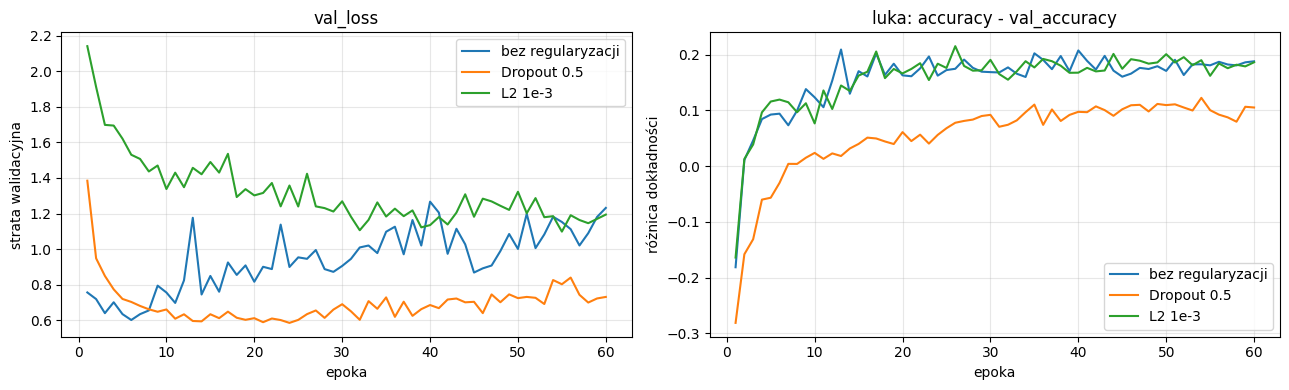

bez regularyzacji : min val_loss 0.602 (epoka 6), val_loss na końcu 1.231 (wzrost o 0.630), luka acc na końcu 0.188
Dropout 0.5       : min val_loss 0.585 (epoka 24), val_loss na końcu 0.731 (wzrost o 0.146), luka acc na końcu 0.105
L2 1e-3           : min val_loss 1.098 (epoka 55), val_loss na końcu 1.194 (wzrost o 0.096), luka acc na końcu 0.187


In [22]:
def zbuduj_regularyzowany(dropout=0.0, l2=0.0, batchnorm=False):
    # Ta sama architektura co zbuduj_przeuczony (3 x 512), z opcjonalną regularyzacją
    keras.utils.set_random_seed(SEED)          # identyczna inicjalizacja -> uczciwe porównanie
    model = keras.Sequential([keras.Input(shape=(28, 28)), layers.Flatten()])
    for _ in range(3):
        reg = keras.regularizers.l2(l2) if l2 > 0 else None
        if batchnorm:
            # Dense (bez aktywacji) -> BatchNorm -> ReLU
            model.add(layers.Dense(512, kernel_regularizer=reg))
            model.add(layers.BatchNormalization())
            model.add(layers.Activation("relu"))
        else:
            model.add(layers.Dense(512, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))     # po aktywacji
    model.add(layers.Dense(10, activation="softmax"))
    return model

h_drop = trenuj_reg(zbuduj_regularyzowany(dropout=0.5))
h_l2 = trenuj_reg(zbuduj_regularyzowany(l2=1e-3))

rysuj_historie(h_drop, tytul="Dropout 0.5")
rysuj_historie(h_l2, tytul="L2 1e-3")

# Porównanie z modelem bez regularyzacji
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nazwa, h in {"bez regularyzacji": h_over, "Dropout 0.5": h_drop, "L2 1e-3": h_l2}.items():
    ep = np.arange(1, len(h["val_loss"]) + 1)
    ax[0].plot(ep, h["val_loss"], label=nazwa)
    ax[1].plot(ep, np.array(h["accuracy"]) - np.array(h["val_accuracy"]), label=nazwa)
ax[0].set_title("val_loss"); ax[0].set_ylabel("strata walidacyjna")
ax[1].set_title("luka: accuracy - val_accuracy"); ax[1].set_ylabel("różnica dokładności")
for a in ax:
    a.set_xlabel("epoka"); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for nazwa, h in {"bez regularyzacji": h_over, "Dropout 0.5": h_drop, "L2 1e-3": h_l2}.items():
    k = int(np.argmin(h["val_loss"]))
    print(f"{nazwa:18s}: min val_loss {h['val_loss'][k]:.3f} (epoka {k + 1}), "
          f"val_loss na końcu {h['val_loss'][-1]:.3f} (wzrost o {h['val_loss'][-1] - h['val_loss'][k]:.3f}), "
          f"luka acc na końcu {h['accuracy'][-1] - h['val_accuracy'][-1]:.3f}")

### Zadanie 5.2 - BatchNormalization i zestawienie

1. Wytrenuj wariant z BatchNorm (`h_bn`) oraz wariant łączony BatchNorm + Dropout 0.3 (`h_bn_drop`).
2. Na jednym wykresie narysuj `val_loss` wszystkich pięciu wariantów (bez regularyzacji, Dropout, L2, BN, BN+Dropout).
3. Zbuduj tabelę: najlepsza `val_accuracy`, `val_accuracy` w ostatniej epoce, różnica `accuracy - val_accuracy` w ostatniej epoce (miara przeuczenia).
4. Sformułuj w markdown **hipotezę** przed uruchomieniem (np. "BN poprawi szybkość, ale słabiej ograniczy przeuczenie niż Dropout") i zweryfikuj ją po wynikach (UGŁ_U01).

**Kryteria sukcesu:** tabela i wykres kompletne, hipoteza zweryfikowana wynikami.

*Hipoteza (przed uruchomieniem):* (1) Dropout 0.5 i L2 najbardziej zmniejszą lukę `accuracy - val_accuracy` i wzrost `val_loss` po minimum. (2) Sam BatchNorm przyspieszy trening (szybszy spadek straty w pierwszych epokach), ale słabo ograniczy przeuczenie - luka train-val będzie zbliżona do modelu bez regularyzacji. (3) BN + Dropout 0.3 da najlepszą lub bliską najlepszej `val_accuracy` przy małej luce, bo łączy stabilny trening z regularyzacją.

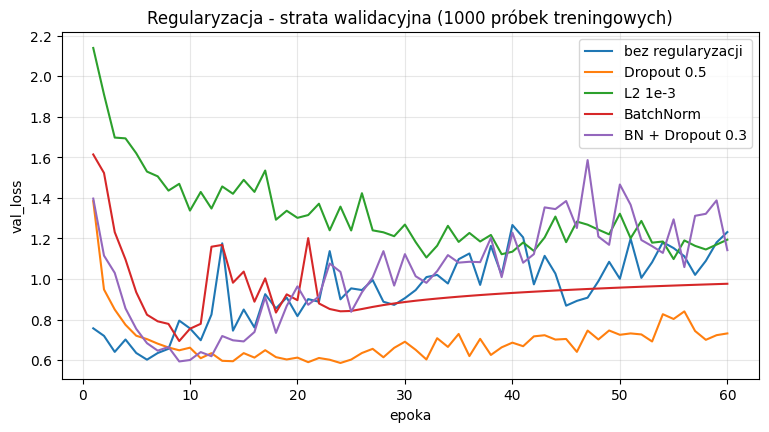

,najlepsza val_accuracy,val_accuracy (ostatnia),accuracy - val_accuracy (ostatnia),min val_loss,epoka min val_loss
bez regularyzacji,0.8166,0.8098,0.1882,0.6017,6
Dropout 0.5,0.8201,0.8127,0.1053,0.5855,24
L2 1e-3,0.8107,0.7775,0.1865,1.0983,55
BatchNorm,0.8151,0.8149,0.1851,0.6937,9
BN + Dropout 0.3,0.8079,0.7977,0.1983,0.5930,9


In [23]:
# 1. Warianty z BatchNorm
h_bn = trenuj_reg(zbuduj_regularyzowany(batchnorm=True))
h_bn_drop = trenuj_reg(zbuduj_regularyzowany(batchnorm=True, dropout=0.3))

warianty = {
    "bez regularyzacji": h_over,
    "Dropout 0.5": h_drop,
    "L2 1e-3": h_l2,
    "BatchNorm": h_bn,
    "BN + Dropout 0.3": h_bn_drop,
}

# 2. val_loss wszystkich pięciu wariantów
plt.figure(figsize=(9, 4.5))
for nazwa, h in warianty.items():
    plt.plot(np.arange(1, len(h["val_loss"]) + 1), h["val_loss"], label=nazwa)
plt.xlabel("epoka"); plt.ylabel("val_loss")
plt.title("Regularyzacja - strata walidacyjna (1000 próbek treningowych)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# 3. Tabela porównawcza
tabela_reg5 = pd.DataFrame({
    "najlepsza val_accuracy": [max(h["val_accuracy"]) for h in warianty.values()],
    "val_accuracy (ostatnia)": [h["val_accuracy"][-1] for h in warianty.values()],
    "accuracy - val_accuracy (ostatnia)": [h["accuracy"][-1] - h["val_accuracy"][-1] for h in warianty.values()],
    "min val_loss": [min(h["val_loss"]) for h in warianty.values()],
    "epoka min val_loss": [int(np.argmin(h["val_loss"])) + 1 for h in warianty.values()],
}, index=list(warianty.keys())).round(4)
display(tabela_reg5)

*Weryfikacja hipotezy:* Wyniki z uruchomienia w Colab (GPU T4, 1000 obrazów treningowych, 60 epok).

(1) **Dropout 0.5 - potwierdzone:** luka accuracy - val_accuracy spadła z 0.188 do 0.105, val_loss po minimum urósł tylko o 0.15 (bez regularyzacji o 0.63), minimum val_loss przesunęło się z 6. na 24. epokę, a najlepsza val_accuracy jest najwyższa ze wszystkich (0.820). **L2 ($\lambda = 10^{-3}$) - niepotwierdzone:** wzrost val_loss po minimum jest najmniejszy (0.10), ale luka accuracy praktycznie się nie zmieniła (0.187 vs 0.188), a val_accuracy w ostatniej epoce jest najniższa (0.778). Uwaga: val_loss dla L2 zawiera karę $\lambda\sum w^2$, więc jego wartość bezwzględna (~1.10) nie jest porównywalna z innymi wariantami.

(2) **BatchNorm - potwierdzone:** luka (0.185) jest prawie taka jak bez regularyzacji, więc przeuczenia BN nie ogranicza. Za to trening jest stabilny - val_accuracy w ostatniej epoce jest najwyższa ze wszystkich (0.815) i prawie równa najlepszej (0.815).

(3) **BN + Dropout 0.3 - niepotwierdzone:** luka 0.198 (największa) i val_accuracy 0.798 - gorzej niż sam Dropout 0.5; przy tak małym zbiorze Dropout 0.3 jest za słaby.

Wszystkie warianty kończą w okolicy 0.78-0.82 val_accuracy: regularyzacja zmniejsza przeuczenie, ale 1000 próbek to po prostu za mało danych.

## 6. Zapis i wczytanie modelu

Wytrenowany model to element cyklu życia systemu (W1, W2): trzeba go zapisać, wersjonować, wczytać w innym procesie (np. serwis predykcyjny). W Keras 3:

| Co | Jak | Zawiera |
|---|---|---|
| pełny model | `model.save("plik.keras")`, `keras.models.load_model("plik.keras")` | architekturę, wagi, konfigurację `compile` i stan optymalizatora |
| tylko wagi | `model.save_weights("plik.weights.h5")`, `model.load_weights(...)` | tylko wartości wag - architekturę trzeba odtworzyć w kodzie |

Format `.keras` to archiwum zip (konfiguracja JSON + wagi). Starszy format `.h5` dla pełnych modeli oraz `SavedModel` są w Keras 3 przestarzałe. **Pamiętaj:** w Colab pliki zapisane na dysku maszyny wirtualnej znikają po zakończeniu sesji - aby je zachować, pobierz je lub zapisz na Google Drive.

Zapis wraz ze stanem optymalizatora pozwala **wznowić trening** dokładnie tam, gdzie go przerwano.

In [24]:
# Demonstracja: zapis i wczytanie pełnego modelu
model_demo.save("model_demo.keras")
wczytany = keras.models.load_model("model_demo.keras")

p1 = model_demo.predict(x_test[:100], verbose=0)
p2 = wczytany.predict(x_test[:100], verbose=0)
print("Predykcje identyczne:", np.allclose(p1, p2, atol=1e-6))
print("Rozmiar pliku: %.1f kB" % (os.path.getsize("model_demo.keras") / 1024))
print("Optymalizator wczytanego modelu:", type(wczytany.optimizer).__name__)

Predykcje identyczne: True
Rozmiar pliku: 1215.3 kB
Optymalizator wczytanego modelu: Adam


### Zadanie 6.1 - Zapis wag i wznowienie treningu

1. Zbuduj funkcją `zbuduj_regularyzowany(dropout=0.5)` model, wytrenuj go 2 epoki na `x_maly` (funkcja `trenuj_reg(model, epoki=2)`) i zapisz **same wagi** do `wagi_dropout.weights.h5`.
2. Zbuduj **nowy** model tą samą funkcją, wczytaj do niego wagi i sprawdź (`np.allclose`), że predykcje na `x_test[:100]` są identyczne. Pamiętaj, że Dropout w `predict` jest wyłączony - dlatego wynik jest deterministyczny.
3. Zapisz pierwszy model w całości do `model_dropout.keras`, wczytaj go i **kontynuuj trening** jeszcze 2 epoki przez `fit` (bez ponownego `compile`!). Wypisz `val_accuracy` przed i po.

**Kryteria sukcesu:** oba sprawdzenia `np.allclose` dają `True`; wczytany model trenuje się dalej bez błędu.

**Wskazówka:** nowy model z kroku 2 nie musi być skompilowany, żeby wczytać wagi i wykonać `predict`.

In [25]:
# 1. Model z Dropoutem, 2 epoki, zapis samych wag
model_a = zbuduj_regularyzowany(dropout=0.5)
trenuj_reg(model_a, epoki=2)
model_a.save_weights("wagi_dropout.weights.h5")
p_a = model_a.predict(x_test[:100], verbose=0)

# 2. Nowy model tą samą funkcją -> wczytanie wag -> porównanie predykcji
model_b = zbuduj_regularyzowany(dropout=0.5)          # nieskompilowany - do predict nie trzeba
p_b_przed = model_b.predict(x_test[:100], verbose=0)
print("Przed wczytaniem wag predykcje identyczne:", np.allclose(p_a, p_b_przed, atol=1e-6), "(oczekiwane False)")
model_b.load_weights("wagi_dropout.weights.h5")
p_b = model_b.predict(x_test[:100], verbose=0)
print("Po wczytaniu wag predykcje identyczne    :", np.allclose(p_a, p_b, atol=1e-6))

# 3. Zapis pełnego modelu (architektura + wagi + compile + stan optymalizatora) i wznowienie treningu
model_a.save("model_dropout.keras")
model_c = keras.models.load_model("model_dropout.keras")
print("Pełny model - predykcje identyczne       :",
      np.allclose(p_a, model_c.predict(x_test[:100], verbose=0), atol=1e-6))
print("Stan optymalizatora wczytany - wykonane kroki:", int(model_c.optimizer.iterations.numpy()))

_, val_acc_przed = model_c.evaluate(x_val, y_val, verbose=0)
model_c.fit(x_maly, y_maly, epochs=2, batch_size=64,          # bez ponownego compile!
            validation_data=(x_val, y_val), verbose=2)
_, val_acc_po = model_c.evaluate(x_val, y_val, verbose=0)
print(f"val_accuracy przed: {val_acc_przed:.4f} -> po wznowieniu: {val_acc_po:.4f}")
print("kroki optymalizatora po wznowieniu:", int(model_c.optimizer.iterations.numpy()))

Przed wczytaniem wag predykcje identyczne: False (oczekiwane False)
Po wczytaniu wag predykcje identyczne    : True
Pełny model - predykcje identyczne       : True
Stan optymalizatora wczytany - wykonane kroki: 32
Epoch 1/2
16/16 - 5s - 301ms/step - accuracy: 0.5830 - loss: 1.1200 - val_accuracy: 0.6938 - val_loss: 0.8583
Epoch 2/2
16/16 - 1s - 33ms/step - accuracy: 0.6510 - loss: 0.9734 - val_accuracy: 0.7042 - val_loss: 0.7735
val_accuracy przed: 0.6442 -> po wznowieniu: 0.7042
kroki optymalizatora po wznowieniu: 64


## Pytania kontrolne

1. Dlaczego w ostatniej warstwie klasyfikatora na 10 klas używamy softmax, a w regresji warstwy liniowej? Co by się stało, gdyby w regresji cen domów użyć sigmoidy?
2. Czym różni się `sparse_categorical_crossentropy` od `categorical_crossentropy`? Kiedy używamy której?
3. Dlaczego `StandardScaler` dopasowujemy tylko do zbioru treningowego? Jak nazywa się błąd polegający na dopasowaniu go do całych danych i jakie ma skutki?
4. Ile parametrów ma warstwa `Dense(64)` po wejściu o wymiarze 8? A `BatchNormalization` po niej (ile z nich jest uczonych gradientowo)?
5. Co robi `restore_best_weights=True` w `EarlyStopping` i dlaczego jest ważne?
6. Wyjaśnij, czym Adam różni się od zwykłego SGD. Dlaczego SGD bez momentum uczy się wolniej?
7. Na wykresie strata walidacyjna rośnie od 8. epoki, a treningowa dalej spada. Jak to nazywamy i jakie trzy działania podejmiesz?
8. Jak działa Dropout w trakcie treningu, a jak w predykcji? Dlaczego przeskalowuje się aktywacje przez $1/(1-p)$?

## Podsumowanie - co warto zapamiętać

- Keras: `Sequential` / `Input` -> `compile(optimizer, loss, metrics)` -> `fit(..., validation_data=...)` -> `evaluate` / `predict`.
- **Klasyfikacja:** wyjście `Dense(K, softmax)` + `sparse_categorical_crossentropy` (etykiety całkowite). **Regresja:** wyjście `Dense(1)` liniowe + MSE (raportuj MAE/RMSE).
- **Normalizuj dane;** parametry skalowania dopasowuj **tylko na train** - inaczej wyciek danych.
- Zawsze porównuj z **baseline'em** (średnia, regresja liniowa) - bez tego nie wiesz, czy sieć cokolwiek daje.
- **Krzywe uczenia** to podstawowe narzędzie diagnostyczne: niedouczenie vs przeuczenie.
- **Callbacki:** `EarlyStopping(restore_best_weights=True)`, `ModelCheckpoint(save_best_only=True)`, `ReduceLROnPlateau`.
- **Learning rate** jest najważniejszym hiperparametrem; Adam (1e-3) to dobry punkt startowy, SGD+momentum - solidna alternatywa.
- **Regularyzacja:** Dropout i L2 zmniejszają lukę train-val; BatchNorm głównie stabilizuje trening; najlepsze lekarstwo to więcej danych.
- Zapis: `.keras` (pełny model, wznowienie treningu) lub `.weights.h5` (same wagi).

## Do sprawozdania końcowego

Z tego laboratorium umieść w sprawozdaniu (zwięźle, maks. 1,5 strony):

1. **Krzywe uczenia** MLP z zad. 1.1 z krótką diagnozą (w której epoce zaczyna się przeuczenie) oraz dokładność testową.
2. **Tabelę regresji** z zad. 2.2 (średnia / regresja liniowa / MLP; MAE i RMSE) i wykres y vs y_pred z komentarzem o obciętych wartościach.
3. **Porównanie optymalizatorów** (zad. 4.1) - wykres i 2-3 zdania interpretacji.
4. **Tabelę regularyzacji** z zad. 5.2 wraz z **hipotezą i jej weryfikacją** (UGŁ_U01).
5. Jedną **propozycję usprawnienia** (UGŁ_U02), np. inny harmonogram lr, AdamW, augmentacja, inna architektura - z uzasadnieniem.

## Zadanie dodatkowe (dla chętnych) - własny callback i harmonogram lr

1. Napisz własny callback `ZatrzymajPrzyDokladnosci(keras.callbacks.Callback)`, który:
   - w `on_epoch_end` zapisuje do listy bieżący learning rate optymalizatora (`float(self.model.optimizer.learning_rate)`),
   - przerywa trening (`self.model.stop_training = True`), gdy `val_accuracy` przekroczy zadany próg (argument konstruktora), i wypisuje komunikat.
2. Wytrenuj MLP 256-128 na Fashion-MNIST z optymalizatorem Adam, którego learning rate jest harmonogramem `keras.optimizers.schedules.CosineDecay(initial_learning_rate=1e-3, decay_steps=...)` (liczba kroków = epoki x liczba batchy na epokę), z progiem 0.89.
3. Narysuj zapisany przez callback przebieg learning rate.

**Wskazówka:** liczba batchy na epokę to `ceil(len(x_train) / batch_size)`.

Epoch 1/20
391/391 - 7s - 18ms/step - accuracy: 0.8158 - loss: 0.5224 - val_accuracy: 0.8561 - val_loss: 0.4147
Epoch 2/20
391/391 - 1s - 3ms/step - accuracy: 0.8652 - loss: 0.3739 - val_accuracy: 0.8643 - val_loss: 0.3832
Epoch 3/20
391/391 - 1s - 3ms/step - accuracy: 0.8786 - loss: 0.3331 - val_accuracy: 0.8723 - val_loss: 0.3655
Epoch 4/20
391/391 - 1s - 3ms/step - accuracy: 0.8880 - loss: 0.3061 - val_accuracy: 0.8760 - val_loss: 0.3499
Epoch 5/20
391/391 - 1s - 3ms/step - accuracy: 0.8951 - loss: 0.2858 - val_accuracy: 0.8753 - val_loss: 0.3477
Epoch 6/20
391/391 - 1s - 3ms/step - accuracy: 0.9021 - loss: 0.2671 - val_accuracy: 0.8742 - val_loss: 0.3467
Epoch 7/20
391/391 - 1s - 3ms/step - accuracy: 0.9080 - loss: 0.2501 - val_accuracy: 0.8779 - val_loss: 0.3492
Epoch 8/20
391/391 - 1s - 4ms/step - accuracy: 0.9136 - loss: 0.2368 - val_accuracy: 0.8782 - val_loss: 0.3520
Epoch 9/20
391/391 - 2s - 5ms/step - accuracy: 0.9181 - loss: 0.2238 - val_accuracy: 0.8871 - val_loss: 0.3321


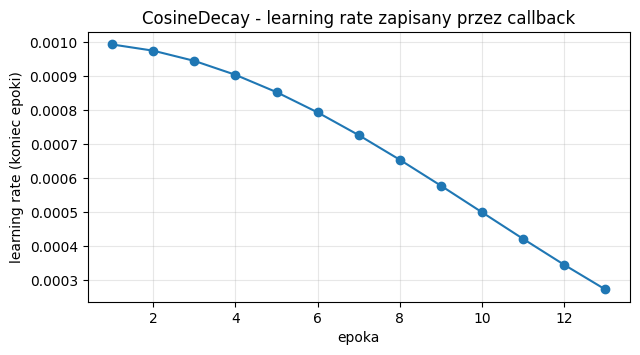

Wykonano 13 z 20 epok; najlepsza val_accuracy = 0.8912


In [26]:
import math

EPOKI_DOD = 2 if SZYBKI_TRYB else 20

class ZatrzymajPrzyDokladnosci(keras.callbacks.Callback):
    # Zapisuje lr po każdej epoce i przerywa trening po przekroczeniu progu val_accuracy
    def __init__(self, prog=0.89):
        super().__init__()
        self.prog = prog
        self.historia_lr = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        # przy harmonogramie optimizer.learning_rate zwraca bieżącą wartość z harmonogramu
        self.historia_lr.append(float(self.model.optimizer.learning_rate))
        val_acc = logs.get("val_accuracy")
        if val_acc is not None and val_acc > self.prog:
            print(f"\nEpoka {epoch + 1}: val_accuracy = {val_acc:.4f} > {self.prog} - zatrzymuję trening.")
            self.model.stop_training = True

BATCH_DOD = 128
kroki_na_epoke = math.ceil(len(x_train) / BATCH_DOD)
harmonogram = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3,
    decay_steps=EPOKI_DOD * kroki_na_epoke,     # lr spada do 0 po wszystkich zaplanowanych krokach
)

keras.utils.set_random_seed(SEED)
model_dod = keras.Sequential([
    keras.Input(shape=(28, 28)), layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model_dod.compile(optimizer=keras.optimizers.Adam(learning_rate=harmonogram),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

stoper = ZatrzymajPrzyDokladnosci(prog=0.89)
hist_dod = model_dod.fit(x_train, y_train, epochs=EPOKI_DOD, batch_size=BATCH_DOD,
                         validation_data=(x_val, y_val), callbacks=[stoper], verbose=2)

plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(1, len(stoper.historia_lr) + 1), stoper.historia_lr, "o-")
plt.xlabel("epoka"); plt.ylabel("learning rate (koniec epoki)")
plt.title("CosineDecay - learning rate zapisany przez callback")
plt.grid(alpha=0.3); plt.show()
print(f"Wykonano {len(hist_dod.history['loss'])} z {EPOKI_DOD} epok; "
      f"najlepsza val_accuracy = {max(hist_dod.history['val_accuracy']):.4f}")